In [2]:
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

REPO_ROOT = Path.cwd().parent      # the folder that contains the platform package `app`
CODE_DIR = Path.cwd()              # the folder with strategy_gp.py, lab.py, platform_bridge.py, ...
for path in (REPO_ROOT, CODE_DIR):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from app.strategies.genetic.experiment import arm0_random, arm1_llm_fully
import app.strategies.genetic.experiment.arm1_llm_fully as arm1
import app.strategies.genetic.experiment.arm5_demo_gp_optuna as arm5
import app.strategies.genetic.llm.lab as lab
import app.strategies.genetic.platform_bridge as pb
from app.strategies.genetic.rule_strategy import RuleStrategy
from app.data.data_provider import GapsFoundError, OHLCVDataProvider

pd.set_option("display.max_colwidth", 140)

F:\Університет\AlphaMiner\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
SYMBOL, EXCHANGE, TIMEFRAME = "BTC/USDT", "binance", "1h"
START = datetime(2022, 1, 1, tzinfo=timezone.utc)
END = datetime(2026, 10, 1, tzinfo=timezone.utc)
HOLDOUT_FRACTION = 0.25  # the last quarter of the bars: never seen by the search
BUDGET = 2000  # backtests per arm and seed (B), the same for both arms
K = 10  # Optuna trials per GP structure
POP = 30  # GP population
SEEDS = [0]  # one seed for a demo; at least five for the experiment
PLATFORM_SEEDS = SEEDS[:1]  # rules handed in under these seeds are re-run on the platform engine
MONEY = 10_000.0
COST_BPS = 12  # fee + slippage per side in the fast engine

lab.BARS_PER_YEAR = pb.BARS_PER_YEAR[TIMEFRAME]
lab.COST_BPS = COST_BPS
STRATEGY = dict(symbol=SYMBOL, exchange=EXCHANGE, timeframe=TIMEFRAME)


def make_provider(strategy, start=START, end=END):
    """A fresh candle provider, built the way the backtest Celery task builds it."""
    return OHLCVDataProvider(strategy, start, end, EXCHANGE, SYMBOL, TIMEFRAME)

In [4]:
 ## 1. Candles
probe = RuleStrategy(**STRATEGY)
try:
    data, stamps = pb.bars_from_provider(make_provider(probe), probe)
except GapsFoundError as err:
    print("The candle store has gaps:", err.gaps)
    raise

N = len(data["close"])
N_SEARCH = int(N * (1 - HOLDOUT_FRACTION))
N_TRAIN = int(N_SEARCH * lab.TRAIN_FRACTION)
print(f"{N} bars, {stamps[0]} .. {stamps[-1]}")
print(f"train {N_TRAIN} bars, validation {N_SEARCH - N_TRAIN}, hold-out {N - N_SEARCH} (from {stamps[N_SEARCH]})")

41615 bars, 2022-01-01 00:00:00+00:00 .. 2026-09-30 23:00:00+00:00
train 21847 bars, validation 9364, hold-out 10404 (from 2025-07-24 12:00:00+00:00)


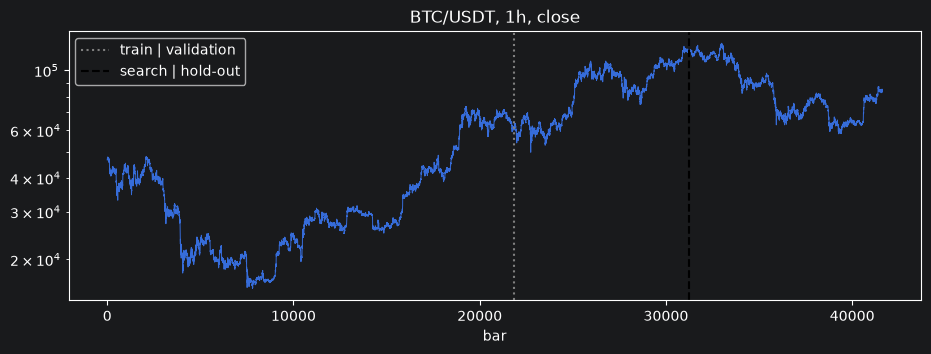

In [5]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(data["close"], lw=0.7)
ax.axvline(N_TRAIN, color="grey", ls=":", label="train | validation")
ax.axvline(N_SEARCH, color="black", ls="--", label="search | hold-out")
ax.set_yscale("log")
ax.set_title(f"{SYMBOL}, {TIMEFRAME}, close")
ax.set_xlabel("bar")
ax.legend()
plt.show()

In [13]:
runs = {}
from dotenv import load_dotenv

import app.strategies.genetic.llm.llm_models as lm

load_dotenv(REPO_ROOT / ".env")              # reads ANTHROPIC_API_KEY (and the other keys) from backend/.env
model = lm.ClaudeModel("claude-haiku-5-5")  # effort="low", caches the system prompt; swap for claude-haiku-5-5 to cut cost

## 0: Random ##


In [8]:
runs = {}
# 0: Random
for seed in SEEDS:
    started = time.perf_counter()
    ledger = arm0_random.random_search(data, BUDGET, seed=seed, n_search=N_SEARCH)
    minutes = (time.perf_counter() - started) / 60
    runs[("0: random", seed)] = {"ledger": ledger, "minutes": minutes}
    print(f"arm 0, seed {seed}: {ledger.used} backtests, {minutes:.1f} min")

arm 0, seed 0: 2000 backtests, 0.2 min


## 1: LLM only ##

In [ ]:
# 1: LLM generates the strategy and tunes parameters -- Claude via the Anthropic Messages API

for seed in SEEDS:
    started = time.perf_counter()
    ledger, generator = arm1.fully_llm_search(data, model=model, seed=seed, budget=BUDGET, n_search=N_SEARCH)
    minutes = (time.perf_counter() - started) / 60
    runs[("1: LLM only", seed)] = {"ledger": ledger, "minutes": minutes}
    print(f"arm 1, seed {seed}: {generator.stats['calls']} calls, {ledger.used} backtests, {minutes:.1f} min")

## 2: GP creates strategy, LLM tunes parameters ##


In [1]:
# 2: GP creates strategy, LLM tunes parameters (the arm-5 engine with Optuna swapped for the model)
import app.strategies.genetic.experiment.arm2_gp_llm_tune as arm2

for seed in SEEDS:
    started = time.perf_counter()
    ledger, generations, stats = arm2.evolve(data, model=model, seed=seed, budget=BUDGET,
                                              pop_size=POP, k=K, n_search=N_SEARCH)
    minutes = (time.perf_counter() - started) / 60
    runs[("2: GP + LLM tune", seed)] = {"ledger": ledger, "minutes": minutes}
    print(f"arm 2, seed {seed}: {generations} generations, {stats['calls']} model calls, "
          f"{ledger.used} backtests, {minutes:.1f} min")

F:\Університет\AlphaMiner\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NameError: name 'SEEDS' is not defined

## 3: LLM creates strategy, Optuna tunes parameters of every strategy ##


In [21]:
# 3: LLM creates strategy, Optuna tunes parameters of every strategy
# --- Kernel ▸ Restart first, then run this cell alone ---
import os, anthropic
from pathlib import Path
from dotenv import load_dotenv, find_dotenv

# locate backend/.env regardless of where the kernel started
hit = find_dotenv(usecwd=True)
env_path = Path(hit) if hit else next(
  p / ".env" for p in [Path.cwd(), *Path.cwd().parents] if (p / ".env").exists())
load_dotenv(env_path, override=True)
key = os.environ.get("ANTHROPIC_API_KEY", "")

import app.strategies.genetic.llm.llm_models as lm
model = lm.ClaudeModel("claude-haiku-5-5",
                     client=anthropic.Anthropic(api_key=key))   # explicit key, no env guesswork

SEEDS = [0]
for seed in SEEDS:
  started = time.perf_counter()
  ledger, generator = arm1.fully_llm_search(data, model=model, seed=seed, budget=BUDGET, n_search=N_SEARCH)
  minutes = (time.perf_counter() - started) / 60
  runs[("3: LLM + Optuna", seed)] = {"ledger": ledger, "minutes": minutes}
  print(f"arm 3, seed {seed}: {generator.stats['calls']} calls, {ledger.used} backtests, {minutes:.1f} min")

loaded: F:\Університет\AlphaMiner\backend\notebooks\.env | len: 106 | prefix: sk-ant-
arm 3, seed 0: 295 calls, 2000 backtests, 28.3 min


## 4: LLM creates strategy, Optuna tunes parameters of finalists ##

In [22]:
# 4: LLM creates strategy, Optuna tunes parameters of finalists
for seed in SEEDS:
    started = time.perf_counter()
    ledger, generator = arm1.fully_llm_search(data, model=model, seed=seed, budget=BUDGET, n_search=N_SEARCH)
    minutes = (time.perf_counter() - started) / 60
    runs[("4: LLM + Optuna, finalists only", seed)] = {"ledger": ledger, "minutes": minutes}
    print(f"arm 4, seed {seed}: {generator.stats['calls']} calls, {ledger.used} backtests, {minutes:.1f} min")

arm 4, seed 0: 326 calls, 2000 backtests, 31.0 min


## 5: GP creates strategy, Optuna tunes parameters of finalists ##


In [23]:
for seed in SEEDS:
    started = time.perf_counter()
    ledger, generations = arm5.evolve(data, seed=seed, budget=BUDGET, pop_size=POP, k=K, n_search=N_SEARCH)
    minutes = (time.perf_counter() - started) / 60
    runs[("5: GP + Optuna", seed)] = {"ledger": ledger, "minutes": minutes}
    print(f"arm 5, seed {seed}: {generations} generations, {ledger.used} backtests, {minutes:.1f} min")

arm 5, seed 0: 18 generations, 2000 backtests, 0.5 min


In [24]:
summary = pd.DataFrame([{"arm": arm, "seed": seed, "minutes": round(run["minutes"], 1),
                         **lab.summarize(data, run["ledger"])}
                        for (arm, seed), run in runs.items()])

checks, curves = [], {}
for _, s in summary.iterrows():
    if not isinstance(s["rule"], str) or s["seed"] not in PLATFORM_SEEDS:
        continue
    result, seconds = pb.run_platform(s["rule"], make_provider, MONEY, **STRATEGY)
    result.buy_and_hold_curve = list(MONEY * data["close"] / data["close"][0])
    platform_curve = np.asarray(result.equity_curve, dtype=float) / MONEY
    free, _ = pb.fast_equity(data, s["rule"], 0.0)
    paid, _ = pb.fast_equity(data, s["rule"], COST_BPS)
    checks.append({
        "arm": s["arm"], "seed": s["seed"], "platform, s": round(seconds),
        **pb.prefixed("platform hold-out", pb.window_metrics(platform_curve, N_SEARCH, lab.BARS_PER_YEAR)),
        **pb.prefixed("fast hold-out, no costs", pb.window_metrics(free, N_SEARCH, lab.BARS_PER_YEAR)),
        **pb.prefixed("fast hold-out, costs", pb.window_metrics(paid, N_SEARCH, lab.BARS_PER_YEAR)),
        "engine: profit %": result.overall_profit_percent,
        "engine: max DD %": result.max_drawdown_percent,
        "engine: win rate %": result.win_rate_percent,
        "engine: sharpe (sqrt 252)": result.sharpe_ratio,
        "engine: alpha": result.alpha
    })
    curves[(s["arm"], s["seed"])] = platform_curve

buy_and_hold = data["close"] / data["close"][0]
checks.append({"arm": "buy & hold",
               **pb.prefixed("platform hold-out", pb.window_metrics(buy_and_hold, N_SEARCH, lab.BARS_PER_YEAR))})
pd.DataFrame(checks)

,arm,seed,"platform, s",platform hold-out: return %,platform hold-out: sharpe,platform hold-out: max DD %,"fast hold-out, no costs: return %","fast hold-out, no costs: sharpe","fast hold-out, no costs: max DD %","fast hold-out, costs: return %","fast hold-out, costs: sharpe","fast hold-out, costs: max DD %",engine: profit %,engine: max DD %,engine: win rate %,engine: sharpe (sqrt 252),engine: alpha
0,3: LLM + Optuna,0.0,38.0,-1.859586,-0.263159,7.907536,-1.859586,-0.263159,7.907536,-4.641270,-0.718322,8.676818,38.953299,7.907536,5.797101,0.1970,0.0019
1,"4: LLM + Optuna, finalists only",0.0,22.0,-22.844670,-0.561231,38.638457,-22.844670,-0.561231,38.638457,-31.826606,-0.900238,44.358475,269.264755,40.953288,23.834197,0.1563,0.0059
2,5: GP + Optuna,0.0,10.0,-25.711240,-0.839275,47.341089,-25.711240,-0.839275,47.341089,-29.186271,-0.996896,47.968211,43.115984,47.341089,32.786885,0.0849,0.0017
3,buy & hold,NaN,NaN,-29.491062,-0.490464,53.742065,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


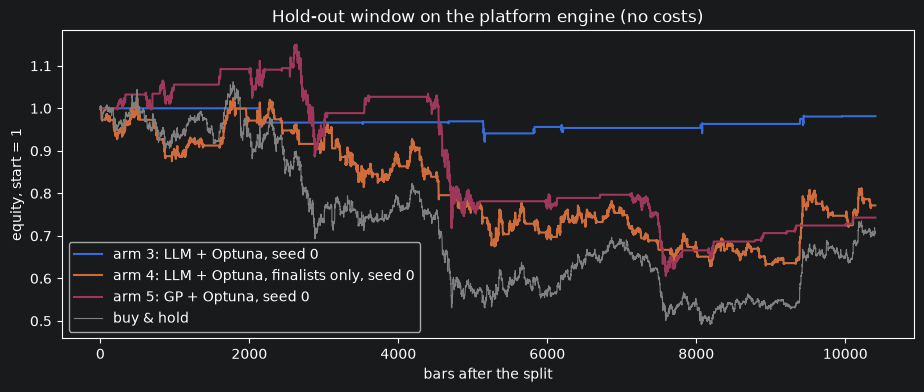

In [25]:
fig, ax = plt.subplots(figsize=(11, 4))
base = N_SEARCH - 1
for (arm, seed), curve in curves.items():
    ax.plot(curve[base:] / curve[base], label=f"arm {arm}, seed {seed}")
ax.plot(buy_and_hold[base:] / buy_and_hold[base], color="grey", lw=0.8, label="buy & hold")
ax.set_title("Hold-out window on the platform engine (no costs)")
ax.set_xlabel("bars after the split")
ax.set_ylabel("equity, start = 1")
ax.legend()
plt.show()

In [26]:
for _, s in summary.iterrows():
      seed = "" if pd.isna(s["seed"]) else f", seed {int(s['seed'])}"
      print(f"\n=== {s['arm']}{seed} ===")
      print(s["rule"] if isinstance(s["rule"], str) else "no rule passed the gates")


=== 3: LLM + Optuna, seed 0 ===
long_flat(and_(z_above(vol_regime(20, 150), 0.5), z_above(mom(close, 10), 1.0)), osc_above(stoch(14), 80.0))

=== 4: LLM + Optuna, finalists only, seed 0 ===
long_flat(cross_up(sma(close, 20), sma(close, 100)), and_(cross_up(sma(close, 105), sma(close, 40)), gt(sma(close, 40), close)))

=== 5: GP + Optuna, seed 0 ===
long_flat(cross_up(high, close), gt(high, sma(lag(close, 15), 372)))
